# Project module: set up the Flan-T5-small RAG language model

**Model:** [google/flan-t5-small](https://huggingface.co/google/flan-t5-small) — the answer generator used by `05_offline_wikipedia_hybrid_rag.ipynb`.

This notebook only downloads and validates the language model and its tokenizer. It uses the same pinned revision as the existing project: `0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab`. The eight selected files total **311,099,876 bytes (about 311 MB / 297 MiB)**, including `model.safetensors`. Alternate weight formats are not downloaded.

**First run:** create the model folder and download missing files automatically. **Later runs:** verify local files and skip valid ones. Partial folders are completed; invalid selected files are re-downloaded. A folder's existence alone does not prove that the model is complete.

The older `offline_wikipedia_rag.ipynb` contains the original model download logic (`prepare_local_model`). The current PGVector notebook uses `local_files_only=True` and loads this model locally; it does not download it.

Run cells from top to bottom. This notebook does not download Wikipedia, load the model into RAM, generate embeddings, create indexes, or change the working RAG notebook. BGE and the MiniLM reranker are separate models and are outside this notebook's scope.

## Portable project folder and database settings
Keep notebooks 01–05 together in the project folder. All data, models and results use paths relative to that folder through `pathlib`, on macOS, Windows or Linux. The code searches the kernel working directory and its parents for notebook 01. Jupyter does not reliably expose the open notebook's file path; if its working directory is elsewhere, set `RAG_PROJECT_DIR` to the project folder before running configuration. A relative override is resolved from the kernel working directory.

Optional override in a cell before configuration:
```python
import os
os.environ['RAG_PROJECT_DIR'] = 'path/to/your/project'  # Relative, or your native absolute path.
```

Database settings in 03–05 follow this precedence: `RAG_PG_DSN` / `RAG_PG_SCHEMA` environment overrides, then `data/rag_setup_connection.json` saved by 03, then the local defaults. On a new machine, run 03 to prepare the connection before 04/05. Supply the PostgreSQL role in the DSN when it differs from your operating-system username. Credentials remain in your environment or PostgreSQL password file; do not put passwords in notebook cells. A saved endpoint is machine-specific: override it when moving to another server. Notebook 03 saves the effective endpoint without its password.

The scope is intentional: notebook 01 downloads **all 41 English shards**, and notebook 04 embeds only **00000–00007** to limit computation. No download or embedding scope is changed by the portable paths.


## A. Project objective and scope

**Deliverable:** a reproducible local copy of the RAG answer generator, ready for the main notebook to load. This module acquires and validates files; it does not train the model or run question answering.

The project separates three responsibilities:

| Notebook | Responsibility |
|---|---|
| `01_download_english_wikipedia_dataset.ipynb` | Acquire the English Wikipedia data and record shard selections |
| `02_setup_rag_llm_flan_t5_small.ipynb` — this file | Acquire and validate Flan-T5-small weights, configuration and tokenizer |
| `05_offline_wikipedia_hybrid_rag.ipynb` | Retrieve evidence from existing indexes and generate answers |

The main RAG also needs its BGE embedding model and MiniLM reranker. Those models perform different jobs and are not downloaded by this module. The PostgreSQL data and SQLite lexical index remain unchanged.

## B. What is T5?

**T5** means **Text-to-Text Transfer Transformer**. It expresses language tasks using a common interface: text goes in and text comes out. For example, a translation task produces translated text, a summarization task produces a summary, and question answering produces an answer. This common format allows knowledge learned during pretraining to transfer to other language tasks. The original research investigated transfer-learning choices using this framework. [Original T5 paper](https://www.jmlr.org/papers/v21/20-074.html).

**Flan-T5** is an instruction-fine-tuned T5 family: additional training uses tasks expressed through instructions. The project downloads `google/flan-t5-small`, not an arbitrary T5 checkpoint. Instruction tuning helps task following but does not guarantee factual correctness. The upstream model card describes intended research use and limitations. [Flan-T5-small model card](https://huggingface.co/google/flan-t5-small).

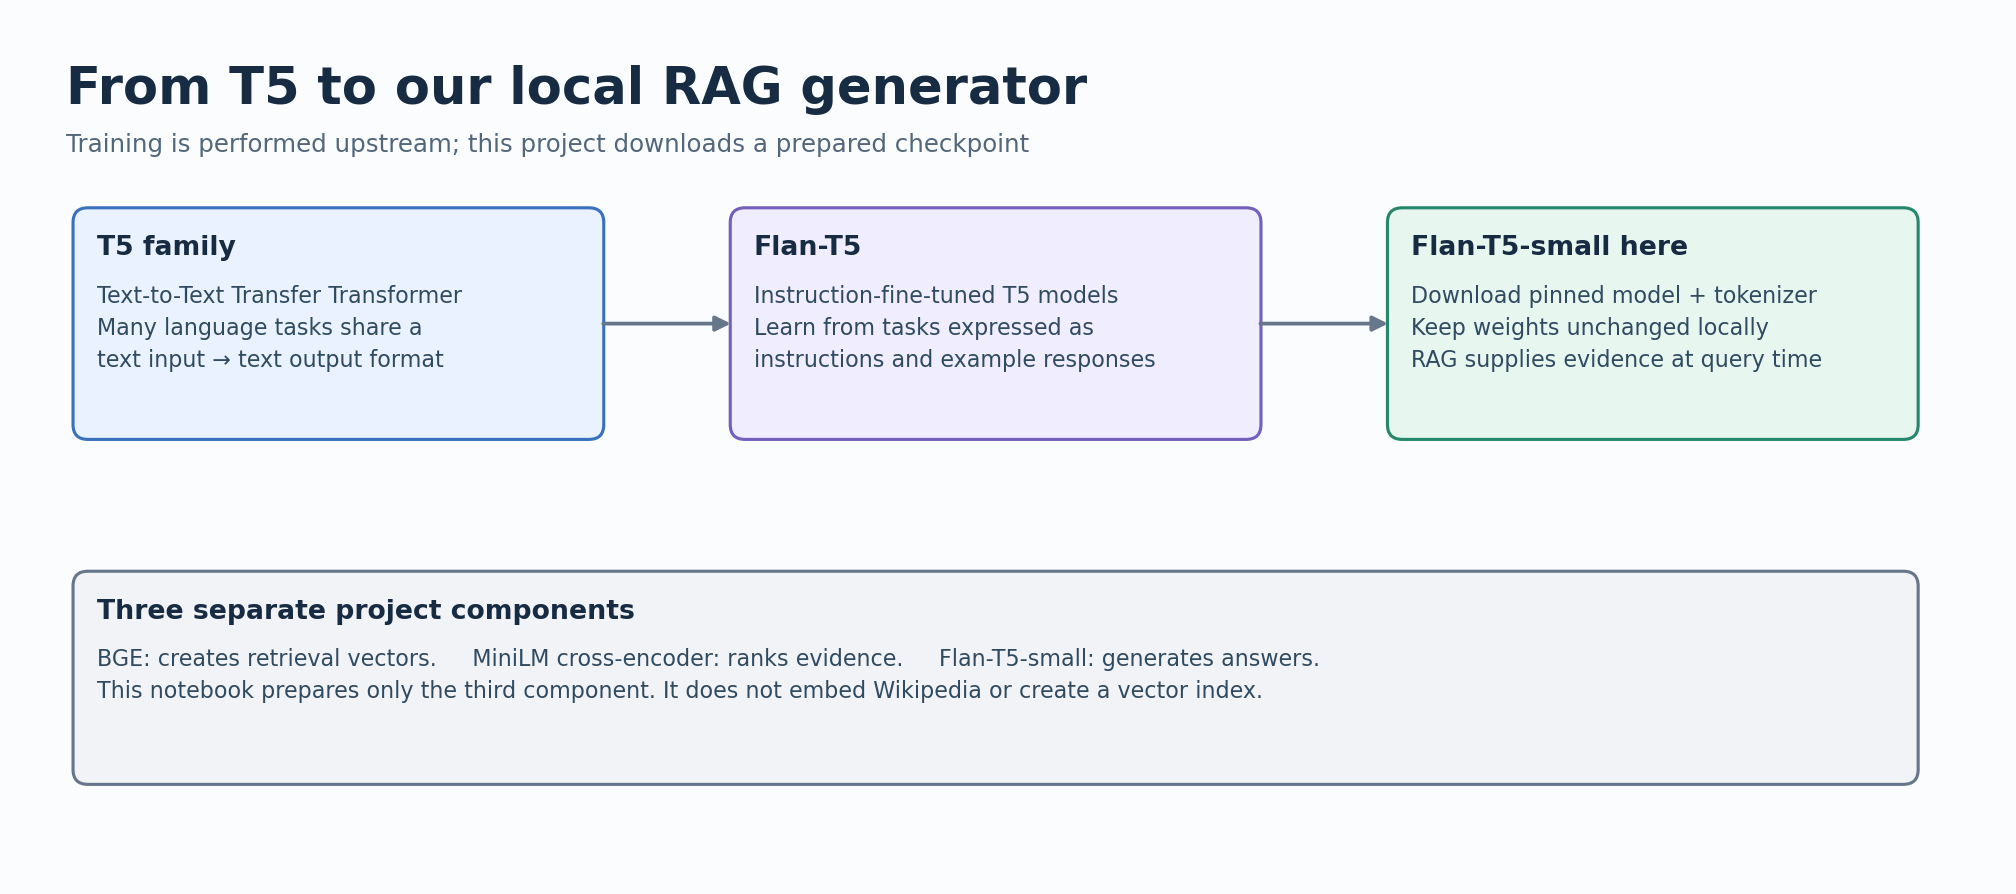

Conceptual relationship between the T5 family, Flan instruction tuning and this project. The download operation does not perform these training stages.

## C. How the encoder and decoder work

The tokenizer converts text to token IDs. The **encoder** builds contextual representations of the input. The **decoder** generates output tokens using both its previous output and the encoder representations. Encoder self-attention relates input tokens; masked decoder self-attention uses preceding output tokens; cross-attention connects the decoder to the encoder. The tokenizer converts generated IDs back into readable text. [T5 implementation documentation](https://huggingface.co/docs/transformers/en/model_doc/t5).

A token is not necessarily a complete word. The output is generated incrementally, rather than retrieved as a prewritten answer from a database.

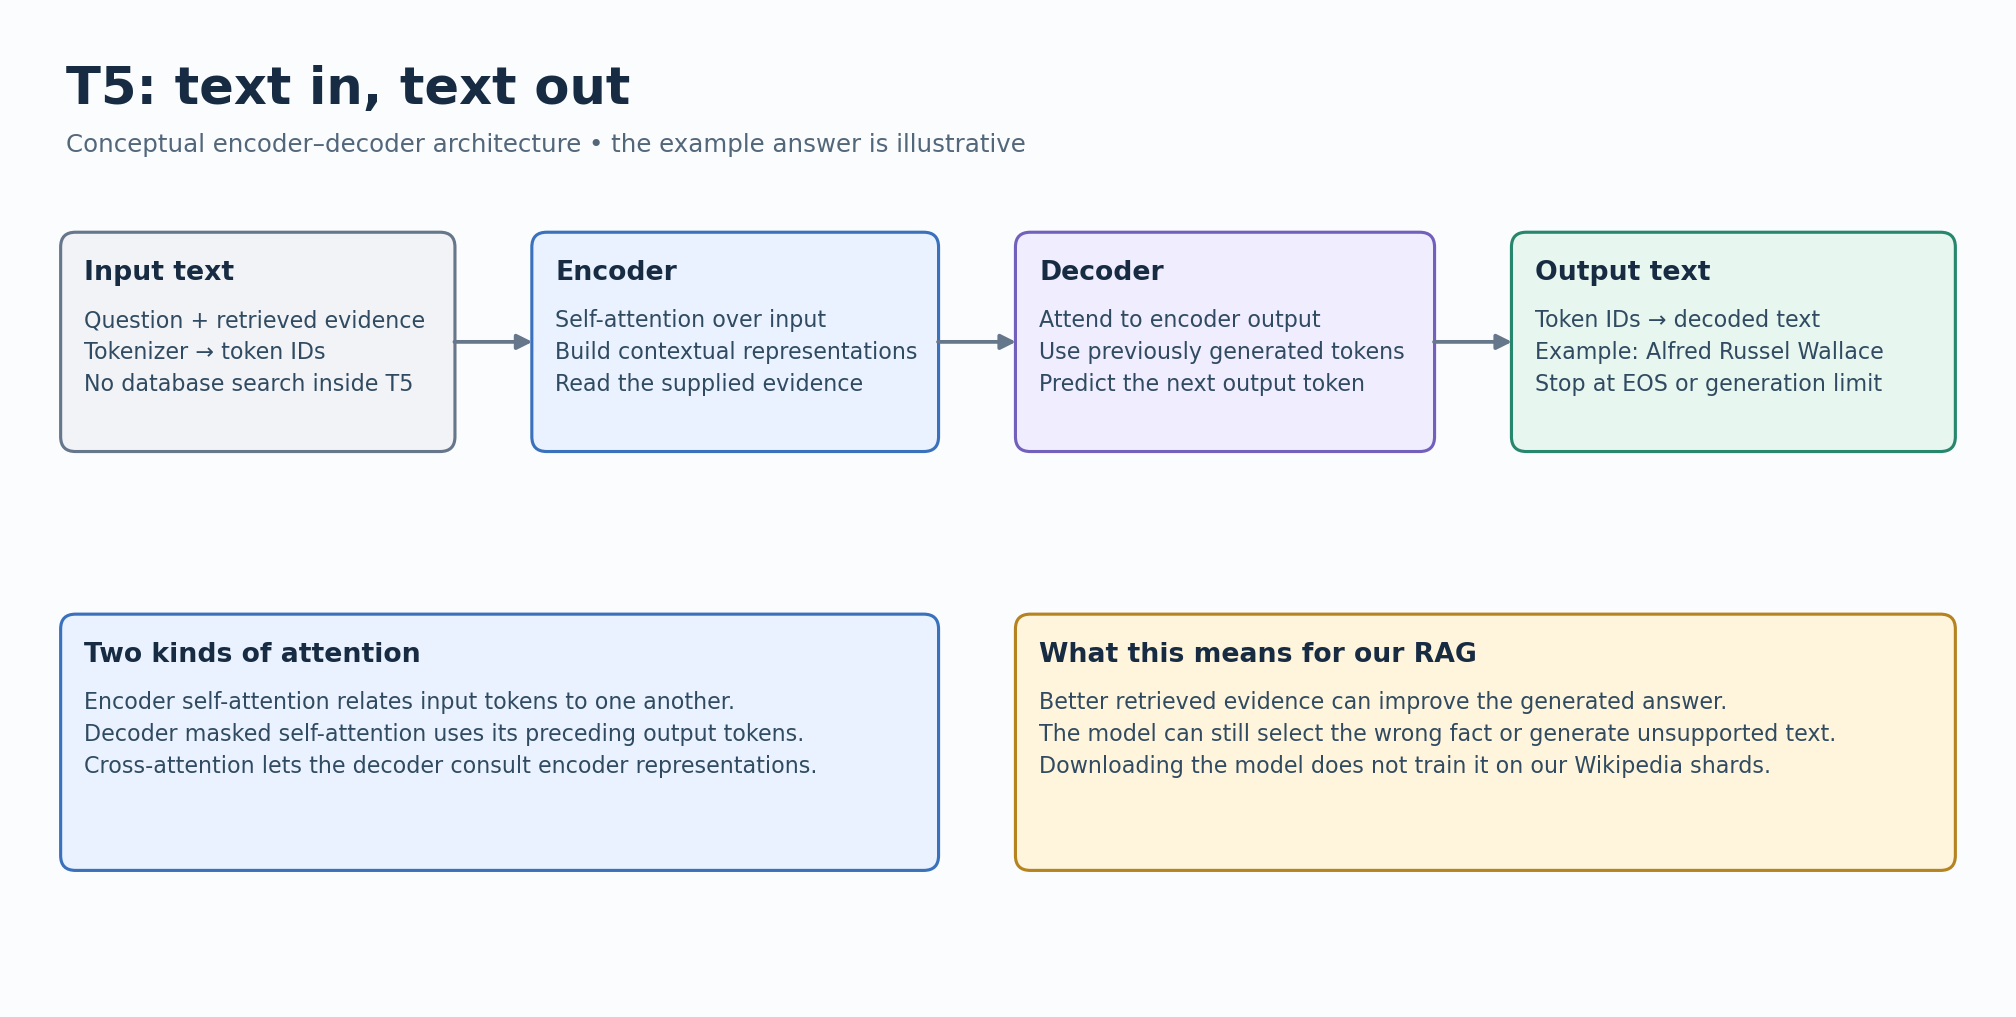

Simplified architecture, not a layer-by-layer implementation diagram. The example illustrates the data flow and does not guarantee an answer for every prompt.

### Configuration of the actual downloaded checkpoint

These values were read from this project's local `models/flan-t5-small/config.json`; they describe this checkpoint rather than every T5 model.

| Configuration field | Local value | Meaning |
|---|---:|---|
| `is_encoder_decoder` | True | Separate encoder and decoder components |
| `num_layers` | 8 | Encoder layers |
| `num_decoder_layers` | 8 | Decoder layers |
| `d_model` | 512 | Hidden representation width |
| `num_heads` | 6 | Attention heads per attention module |
| `d_ff` | 1024 | Feed-forward intermediate width |
| `vocab_size` | 32,128 | Configured vocabulary size |
| `feed_forward_proj` | gated-gelu | Feed-forward projection variant |

Do not confuse **512 hidden dimensions** here with **384-dimensional BGE retrieval vectors** or the RAG's **512-token input budget**. These are separate quantities. This setup notebook preserves the checkpoint configuration; it does not tune these values.

## D. Why this model is used in our RAG

The project specification requires Flan-T5-small for grounded generation. The prepared local file set is approximately 311 MB, making it practical to store alongside the project. Disk size is not the same as inference RAM usage: loading and executing a model also needs runtime memory.

In the working RAG, BGE retrieves semantic candidates, BM25 retrieves lexical candidates, and a cross-encoder reranks evidence. Only then does Flan receive the question and selected source excerpts. Its encoder is **not** the component querying pgvector. The RAG supplies evidence through the prompt without updating Flan's weights.

The current RAG uses an explicit 512-token input budget, deterministic four-beam decoding and up to 160 output tokens. Those generation settings live in the RAG notebook, not here. A maximum output allowance does not force long answers: a factual question may legitimately produce only a name. The model can still select a wrong fact or generate unsupported text even with useful evidence. A successful download proves file availability and integrity, not answer accuracy.

**Example workflow:** the RAG selects a source excerpt naming Alfred Russel Wallace, includes it with the Darwin question, and asks Flan to generate an answer. This downloader neither searches for Wallace nor contains a rule mapping the question to its answer.

## E. What is downloaded, and why?

The inventory pins revision `0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab` so all files come from the same checkpoint. The destination is `models/flan-t5-small/`, which already matches the main RAG's `MODEL_DIR`.

| File | Role in local model loading |
|---|---|
| `model.safetensors` | Learned numerical weights in the format loaded by the RAG |
| `config.json` | Architecture and model configuration |
| `generation_config.json` | Checkpoint generation defaults; the RAG can override them |
| `spiece.model` | SentencePiece tokenizer model |
| `tokenizer.json` | Serialized fast-tokenizer representation |
| `tokenizer_config.json` | Tokenizer settings |
| `special_tokens_map.json` | Special-token definitions |
| `README.md` | Upstream model documentation |

Downloading the tokenizer together with the weights keeps token IDs and model expectations consistent. The notebook additionally writes `download_manifest.json` after successful validation. This manifest is a local record, not a model weight file.

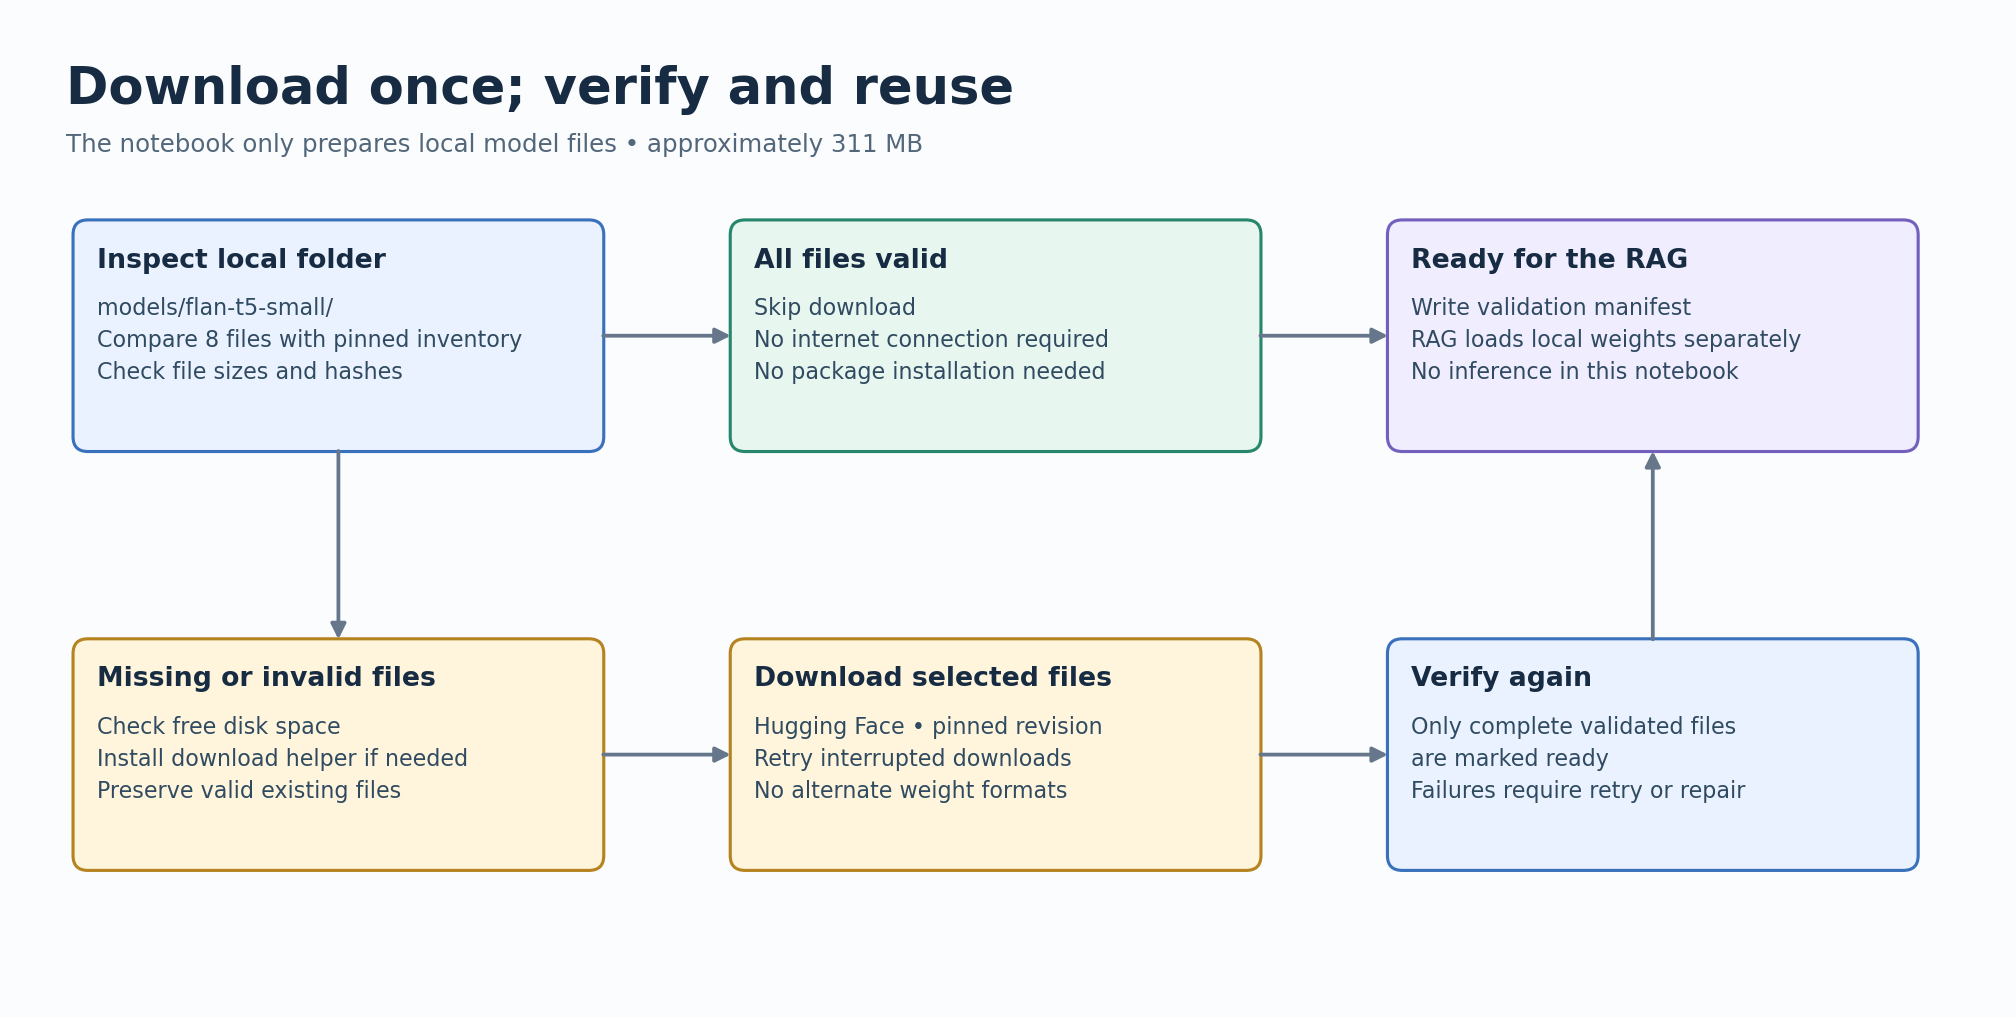

Operational flow of this notebook. Complete valid files bypass the network; only missing or invalid inventory entries are requested.

## F. Reuse, integrity checks and project hand-off

1. Inspect the eight expected local files against the embedded inventory.
2. Verify file sizes and, by default, checksums. SHA-256 is used where supplied; smaller Git-managed files use Git blob SHA-1, which includes a header and is not the ordinary file SHA-1.
3. If all files pass, skip downloading and dependency installation. If files are missing or invalid, check space and download those entries only.
4. Validate again before marking the model ready. Interrupted downloads can be retried by rerunning the notebook.
5. Record the revision, file inventory and validation level in the local manifest.

The only download dependency is `huggingface-hub`. It is installed only if missing and needed for an actual transfer. Downloads use a subprocess to avoid inherited offline flags blocking first-time setup; the parent kernel's environment is retained. The main RAG continues to load files with `local_files_only=True`.

### Completion criteria

- All eight files pass the configured validation, not merely exist in a folder.
- The local directory matches the RAG's model path.
- The model revision and validation level are recorded.
- Repeating setup with valid files skips network activity.

These checks were tested with the real local file checksums and simulated missing/corrupt-file scenarios. Model quality and RAG retrieval accuracy are tested separately in the RAG evaluation suite.

### Viva questions

- **What is the difference between downloading and training?** Downloading copies existing weights; training updates weights using data and a learning objective.
- **Why pin a revision?** To reproduce the same file set rather than silently combining versions.
- **Is Flan the vector database?** No. It generates text after retrieval; pgvector stores/searches passage vectors.
- **Why can a valid model still answer incorrectly?** File integrity does not establish that the evidence is sufficient or that the generated claim follows from it.

The executable setup cells below retain the tested download-only logic. No training, inference or database operations have been added.

## 1. Local path and download settings

The default folder is `IITB-DL/models/flan-t5-small/`, matching the RAG notebook. Change `PROJECT_DIR` when using another computer. Downloads are enabled for first-time setup; a complete validated folder needs no internet connection.

`VERIFY_HASHES=True` checks every selected file against the pinned inventory. Set it to False for faster size-only checks, which cannot detect same-size corruption.

In [6]:
from pathlib import Path
import hashlib, importlib.util, json, os, shutil, subprocess, sys

# Paths are relative to the project folder, using native macOS/Windows separators.
def resolve_project_root():
    override = os.environ.get('RAG_PROJECT_DIR')
    if override:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError('RAG_PROJECT_DIR must point to an existing project folder.')
        return folder
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        if (folder/'01_download_english_wikipedia_dataset.ipynb').is_file():
            return folder
    raise RuntimeError('Open Jupyter from the folder containing notebooks 01–05, or set RAG_PROJECT_DIR to that folder.')

ROOT = resolve_project_root()
PROJECT_DIR = ROOT
MODEL_DIR = PROJECT_DIR / 'models' / 'flan-t5-small'
MODEL_ID = 'google/flan-t5-small'
MODEL_REVISION = '0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab'
ALLOW_DOWNLOADS = True
VERIFY_HASHES = True  # Reads ~311 MB; detects same-size corruption as well as missing files.
DOWNLOAD_WORKERS = 4
INSTALL_MISSING_DEPENDENCY = True  # Only huggingface_hub, only when downloading is necessary.


## 2. Pinned file inventory

Weights, configuration and tokenizer files are kept together at one revision. Large files have SHA-256 values; smaller repository files have Git blob SHA-1 identifiers. The inventory is embedded so checking an existing model does not require contacting Hugging Face.

In [7]:
MODEL_SPEC = {'repo_id': 'google/flan-t5-small', 'repo_type': 'model', 'revision': '0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab', 'files': [{'path': 'README.md', 'size': 10820, 'git_sha1': '245f4a935cf3b2c65ed3d0c1a11b15fd6ab43b80'}, {'path': 'config.json', 'size': 1401, 'git_sha1': '360a0073f29a105ced4a366cda27e668b11bb73b'}, {'path': 'generation_config.json', 'size': 147, 'git_sha1': 'd52815623b46b7db1c4b957b5a83a8ad30b0146a'}, {'path': 'model.safetensors', 'size': 307867048, 'sha256': '495fa51e204676f1a857a9fc13c4c89f3f5ba9f480b898cebca02add25e6d749'}, {'path': 'special_tokens_map.json', 'size': 2201, 'git_sha1': '2c19eb6e3b583f52d34b903b5978d3d30b6b7682'}, {'path': 'spiece.model', 'size': 791656, 'sha256': 'd60acb128cf7b7f2536e8f38a5b18a05535c9e14c7a355904270e15b0945ea86'}, {'path': 'tokenizer.json', 'size': 2424064, 'git_sha1': 'fc669fbad1a6a82119ca3e1fa75db33ee22ca47d'}, {'path': 'tokenizer_config.json', 'size': 2539, 'git_sha1': 'db13bf98b7714acc4dea7621ff7f4ab93f64258e'}], 'total_bytes': 311099876}

## 3. Reuse, download and repair helpers

Only missing or invalid selected files are requested. Valid files and unrelated files in the folder are retained. The downloader runs in a subprocess that enables network downloads even if a previous RAG session set Hugging Face offline flags; the parent kernel's environment is unchanged.

Only `huggingface-hub` is needed for downloading and is installed only when absent and a download is required. PyTorch and Transformers are not installed here. A conservative free-space check runs before download. On failure or interruption, rerun to retry using the local download cache.

In [8]:
def _download_files(destination: Path, spec: dict, entries: list[dict], max_workers: int):
    # A fresh process can download even if an earlier notebook cell imported Hub
    # with HF_HUB_OFFLINE=1. The parent kernel's offline settings remain unchanged.
    payload = {
        "repo_id": spec["repo_id"], "repo_type": spec["repo_type"], "revision": spec["revision"],
        "local_dir": str(destination.resolve()), "max_workers": max_workers,
        "missing": [e["path"] for e in entries if not (destination / e["path"]).exists()],
        "repair": [e["path"] for e in entries if (destination / e["path"]).exists()],
    }
    program = '''
import json, sys
from huggingface_hub import snapshot_download
p = json.load(sys.stdin)
for group, force in (("missing", False), ("repair", True)):
    if p[group]:
        snapshot_download(
            repo_id=p["repo_id"], repo_type=p["repo_type"], revision=p["revision"],
            local_dir=p["local_dir"], allow_patterns=p[group],
            force_download=force, max_workers=p["max_workers"],
        )
'''
    environment = os.environ.copy()
    for name in ("HF_HUB_OFFLINE", "HF_DATASETS_OFFLINE", "TRANSFORMERS_OFFLINE"):
        environment[name] = "0"
    environment["HF_HUB_DISABLE_TELEMETRY"] = "1"
    environment["HF_XET_CACHE"] = str(destination / ".cache/huggingface/xet")
    with subprocess.Popen(
        [sys.executable, "-u", "-c", program], stdin=subprocess.PIPE,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=environment,
    ) as process:
        try:
            process.stdin.write(json.dumps(payload))
            process.stdin.close()
            for line in process.stdout:
                print(line, end="", flush=True)
            if process.wait() != 0:
                raise RuntimeError("Dataset download interrupted or failed. Rerun to resume.")
        except BaseException:
            if process.poll() is None:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
            raise

def validate_spec(spec):
    if (spec['repo_id'],spec['repo_type'],spec['revision']) != (MODEL_ID,'model',MODEL_REVISION):
        raise ValueError('Model inventory does not match the pinned Flan-T5-small revision.')
    expected={'README.md','config.json','generation_config.json','model.safetensors',
              'special_tokens_map.json','spiece.model','tokenizer.json','tokenizer_config.json'}
    if len(spec['files'])!=len(expected) or {e['path'] for e in spec['files']}!=expected:
        raise ValueError('Unexpected model files; do not mix inventories or revisions.')
    if sum(e['size'] for e in spec['files'])!=spec['total_bytes']:
        raise ValueError('Invalid inventory size.')

def valid_file(path,entry,verify_hashes=True):
    if not path.is_file() or path.stat().st_size!=entry['size']:return False
    if not verify_hashes:return True
    if 'sha256' in entry:
        digest=hashlib.sha256();expected=entry['sha256']
    else:
        # Hugging Face Git blob IDs include this header; they are not plain-file SHA-1.
        digest=hashlib.sha1(f"blob {entry['size']}\0".encode());expected=entry['git_sha1']
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()==expected

def model_status(destination,spec,verify_hashes=True):
    invalid=[e for e in spec['files'] if not valid_file(Path(destination)/e['path'],e,verify_hashes)]
    return dict(total=len(spec['files']),valid=len(spec['files'])-len(invalid),
                missing_or_invalid=invalid,bytes_to_download=sum(e['size'] for e in invalid),complete=not invalid)

def ensure_dependency():
    if importlib.util.find_spec('huggingface_hub') is None:
        if not INSTALL_MISSING_DEPENDENCY:raise RuntimeError('Install huggingface-hub in the notebook kernel first.')
        subprocess.check_call([sys.executable,'-m','pip','install','huggingface-hub==0.36.2'])

def ensure_model(destination,spec,*,allow_download=True,verify_hashes=True,max_workers=4):
    validate_spec(spec)
    if type(max_workers) is not int or max_workers<1:raise ValueError('max_workers must be a positive integer.')
    destination=Path(destination);status=model_status(destination,spec,verify_hashes)
    print(f"Valid local model files: {status['valid']}/{status['total']}",flush=True)
    if status['complete']:
        print('Model already present and validated. Download skipped; no network needed.')
        return status
    if not allow_download:raise FileNotFoundError('Model files are missing/invalid. Enable ALLOW_DOWNLOADS while online.')
    destination.mkdir(parents=True,exist_ok=True)
    required=status['bytes_to_download']+256*1024**2
    free=shutil.disk_usage(destination).free
    if free<required:raise OSError(f'Need about {required/1e6:.1f} MB free including working reserve; available: {free/1e6:.1f} MB.')
    ensure_dependency()
    print(f"Downloading/resuming {len(status['missing_or_invalid'])} model files; progress follows.",flush=True)
    _download_files(destination,spec,status['missing_or_invalid'],max_workers)
    status=model_status(destination,spec,verify_hashes)
    if not status['complete']:raise RuntimeError('Model download incomplete. Rerun to retry missing/invalid files.')
    print('Flan-T5-small is available locally.')
    return status


## 4. Download only if needed

Progress is shown for actual transfers. If all files validate, this cell reports that downloading was skipped. No hosted inference or model generation is performed.

In [9]:
print('Model:',MODEL_ID)
print('Pinned revision:',MODEL_REVISION)
print('Destination:',MODEL_DIR)
status=ensure_model(MODEL_DIR,MODEL_SPEC,allow_download=ALLOW_DOWNLOADS,
                    verify_hashes=VERIFY_HASHES,max_workers=DOWNLOAD_WORKERS)


Model: google/flan-t5-small
Pinned revision: 0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab
Destination: /Users/amolsingh/Documents/code/IITB-DL/models/flan-t5-small
Valid local model files: 8/8
Model already present and validated. Download skipped; no network needed.


## 5. Record the validated local model

This small manifest records paths, revision and validation level for reproducibility. It is written only after all files pass the selected checks. The downloader always checks the actual files rather than trusting a potentially stale completion manifest.

In [10]:
if not status['complete']:raise RuntimeError('Model is not complete; no manifest will be written.')
manifest=dict(model=MODEL_ID,revision=MODEL_REVISION,complete=True,
              validation='hashes' if VERIFY_HASHES else 'file_size',
              total_bytes=MODEL_SPEC['total_bytes'],files=MODEL_SPEC['files'])
path=MODEL_DIR/'download_manifest.json'
temp=path.with_suffix('.tmp');temp.write_text(json.dumps(manifest,indent=2)+chr(10));temp.replace(path)
print('Ready for local RAG loading:',MODEL_DIR)
print('Manifest:',path)


Ready for local RAG loading: /Users/amolsingh/Documents/code/IITB-DL/models/flan-t5-small
Manifest: /Users/amolsingh/Documents/code/IITB-DL/models/flan-t5-small/download_manifest.json


## Next step

Open `05_offline_wikipedia_hybrid_rag.ipynb` to run question answering. Its `MODEL_DIR` already points to this folder, and its generator uses the local safetensors weights and tokenizer. There is no need to rebuild embeddings or the HNSW index after validating this unchanged model.

On a new computer, the RAG also needs its embedding model, reranker, database and aligned lexical index. Downloading Flan-T5-small alone does not reproduce the complete RAG environment.